In [10]:
# FLA CLA-2 Project Setup & Corrected Task 2 - Email Validation

!apt-get -qq update
!apt-get -qq install graphviz
!pip install -q graphviz pandas matplotlib

import re
import os
import pandas as pd
import matplotlib.pyplot as plt
from graphviz import Digraph
from IPython.display import display, HTML
from google.colab import files

print("=" * 55)
print("FORMAL LANGUAGE AND AUTOMATA - CLA 2")
print("Interactive Automata and Language Processing System")
print("=" * 55)

# Corrected Email DFA Implementation representing L = { A+ @ A+ . [A-Za-z]{2,} }
# States:
# q0: Start State
# q1: Username part (must have at least one alphanumeric character)
# q2: Received '@'
# q3: Domain name part (must have at least one alphanumeric character)
# q4: Received '.'
# q5: First letter of extension
# q6: Second letter of extension (Accepting State)
# q7: Additional letters of extension (Accepting State)
# DEAD: Dead State

def email_transition(state, char):
    if state == "DEAD":
        return "DEAD"

    is_alnum = char.isalnum() and char.isascii()
    is_alpha = char.isalpha() and char.isascii()

    if state == "q0":
        return "q1" if is_alnum else "DEAD"
    elif state == "q1":
        if is_alnum:
            return "q1"
        elif char == '@':
            return "q2"
        return "DEAD"
    elif state == "q2":
        return "q3" if is_alnum else "DEAD"
    elif state == "q3":
        if is_alnum:
            return "q3"
        elif char == '.':
            return "q4"
        return "DEAD"
    elif state == "q4":
        return "q5" if is_alpha else "DEAD"
    elif state == "q5":
        return "q6" if is_alpha else "DEAD"
    elif state == "q6":
        return "q7" if is_alpha else "DEAD"
    elif state == "q7":
        return "q7" if is_alpha else "DEAD"
    return "DEAD"

def validate_email(email):
    state = "q0"
    trace = [state]
    for char in email:
        state = email_transition(state, char)
        trace.append(state)
    is_accepted = state in ["q6", "q7"]
    return is_accepted, trace

# Defining the test cases as requested
tests = [
    ("user@gmail.com", "ACCEPTED"),
    ("student123@srm.edu", "ACCEPTED"),
    ("abc@xyz.org", "ACCEPTED"),
    ("x9@host.net", "ACCEPTED"),
    ("a1@b2.in", "ACCEPTED"),
    ("user@.com", "REJECTED"),
    ("@gmail.com", "REJECTED"),
    ("usergmail.com", "REJECTED"),
    ("user@domain.c", "REJECTED"),
    ("user@domain.123", "REJECTED")
]

# Execute tests and construct results DataFrame
results = []
for email, expected in tests:
    accepted, trace = validate_email(email)
    actual = "ACCEPTED" if accepted else "REJECTED"
    results.append({
        "Input": email,
        "Expected": expected,
        "Actual": actual,
        "Result": "PASS" if expected == actual else "FAIL"
    })

email_dfa_results = pd.DataFrame(results)

print("\n--- EMAIL DFA TRANSITION LOGIC VERIFIED ---")
print("Accepted format: Alphanumeric+ @ Alphanumeric+ . Alpha{2,}")
print("-" * 65)
print(email_dfa_results.to_string(index=False))
print("-" * 65)

# Count accepted and rejected
counts = email_dfa_results["Actual"].value_counts()
print(f"Total Accepted: {counts.get('ACCEPTED', 0)}")
print(f"Total Rejected: {counts.get('REJECTED', 0)}")

# Verify user@.com is specifically rejected
user_dot_com_res = email_dfa_results[email_dfa_results["Input"] == "user@.com"]["Actual"].values[0]
print(f"Verification: 'user@.com' has been {user_dot_com_res}.")

# Export to CSV
csv_path = "/content/FLA_Email_DFA_Corrected_Results.csv"
email_dfa_results.to_csv(csv_path, index=False)
print(f"Saved results to {csv_path}")

# Auto-download in Google Colab
files.download(csv_path)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
FORMAL LANGUAGE AND AUTOMATA - CLA 2
Interactive Automata and Language Processing System

--- EMAIL DFA TRANSITION LOGIC VERIFIED ---
Accepted format: Alphanumeric+ @ Alphanumeric+ . Alpha{2,}
-----------------------------------------------------------------
             Input Expected   Actual Result
    user@gmail.com ACCEPTED ACCEPTED   PASS
student123@srm.edu ACCEPTED ACCEPTED   PASS
       abc@xyz.org ACCEPTED ACCEPTED   PASS
       x9@host.net ACCEPTED ACCEPTED   PASS
          a1@b2.in ACCEPTED ACCEPTED   PASS
         user@.com REJECTED REJECTED   PASS
        @gmail.com REJECTED REJECTED   PASS
     usergmail.com REJECTED REJECTED   PASS
     user@domain.c REJECTED REJECTED   PASS
   user@domain.123 REJECTED REJECTED   PASS
-----------------------------------------------------------------
To

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ATM PIN VALIDATION USING DFA
Accepted PIN format: Exactly 4 digits
-----------------------------------------------------------------


,ATM PIN,Result,State Trace
0,'1234',ACCEPTED,q0 → q1 → q2 → q3 → q4
1,'0000',ACCEPTED,q0 → q1 → q2 → q3 → q4
2,'9876',ACCEPTED,q0 → q1 → q2 → q3 → q4
3,'2468',ACCEPTED,q0 → q1 → q2 → q3 → q4
4,'1357',ACCEPTED,q0 → q1 → q2 → q3 → q4
5,'123',REJECTED,q0 → q1 → q2 → q3
6,'12345',REJECTED,q0 → q1 → q2 → q3 → q4 → q_dead
7,'12a4',REJECTED,q0 → q1 → q2 → q_dead → q_dead
8,'',REJECTED,q0
9,'123 ',REJECTED,q0 → q1 → q2 → q3 → q_dead


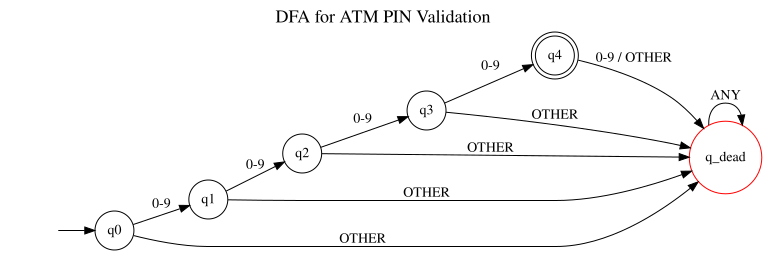


Final State: q4
A PIN is accepted only if the DFA finishes in q4.


In [11]:
# TASK 2 - APPLICATION 1
# ATM PIN Validation using Deterministic Finite Automaton (DFA)

# Define DFA states
states = ["q0", "q1", "q2", "q3", "q4", "q_dead"]
start_state = "q0"
final_states = ["q4"]

digits = "0123456789"

# DFA transition function
def pin_transition(state, symbol):

    if state == "q_dead":
        return "q_dead"

    if symbol not in digits:
        return "q_dead"

    if state == "q0":
        return "q1"
    elif state == "q1":
        return "q2"
    elif state == "q2":
        return "q3"
    elif state == "q3":
        return "q4"
    elif state == "q4":
        return "q_dead"

# PIN validation function
def validate_pin(pin):

    current_state = start_state
    trace = [current_state]

    for symbol in pin:
        current_state = pin_transition(current_state, symbol)
        trace.append(current_state)

    accepted = current_state in final_states

    return accepted, trace


# Test cases
test_cases = [
    "1234",
    "0000",
    "9876",
    "2468",
    "1357",
    "123",
    "12345",
    "12a4",
    "",
    "123 "
]

results = []

for pin in test_cases:

    accepted, trace = validate_pin(pin)

    results.append({
        "ATM PIN": repr(pin),
        "Result": "ACCEPTED" if accepted else "REJECTED",
        "State Trace": " → ".join(trace)
    })

# Display results
df_pin = pd.DataFrame(results)

print("ATM PIN VALIDATION USING DFA")
print("Accepted PIN format: Exactly 4 digits")
print("-" * 65)

display(df_pin)


# Draw DFA diagram
pin_dfa = Digraph("ATM_PIN_DFA", format="png")

pin_dfa.attr(rankdir="LR", label="DFA for ATM PIN Validation",
             labelloc="t", fontsize="18")

pin_dfa.attr("node", shape="circle")

pin_dfa.node("start", shape="none", label="")
pin_dfa.edge("start", "q0")

for state in states:
    if state == "q4":
        pin_dfa.node(state, shape="doublecircle")
    else:
        pin_dfa.node(state)

pin_dfa.node("q_dead", shape="circle", color="red")

# Valid digit transitions
pin_dfa.edge("q0", "q1", label="0-9")
pin_dfa.edge("q1", "q2", label="0-9")
pin_dfa.edge("q2", "q3", label="0-9")
pin_dfa.edge("q3", "q4", label="0-9")

# Extra digit and invalid character transitions
pin_dfa.edge("q4", "q_dead", label="0-9 / OTHER")
pin_dfa.edge("q0", "q_dead", label="OTHER")
pin_dfa.edge("q1", "q_dead", label="OTHER")
pin_dfa.edge("q2", "q_dead", label="OTHER")
pin_dfa.edge("q3", "q_dead", label="OTHER")

# Dead state loops
pin_dfa.edge("q_dead", "q_dead", label="ANY")

display(pin_dfa)

print("\nFinal State: q4")
print("A PIN is accepted only if the DFA finishes in q4.")

PASSWORD VALIDATION USING DFA
Length: 8-12 | Uppercase | Lowercase | Digit | Special Character
------------------------------------------------------------------------------------------


,Password,Result,State Trace
0,Hello@123,ACCEPTED,"(0, ----) → (1, U---) → (2, UL--) → (3, UL--) ..."
1,Student#9,ACCEPTED,"(0, ----) → (1, U---) → (2, UL--) → (3, UL--) ..."
2,Abcd@1234,ACCEPTED,"(0, ----) → (1, U---) → (2, UL--) → (3, UL--) ..."
3,Python$456,ACCEPTED,"(0, ----) → (1, U---) → (2, UL--) → (3, UL--) ..."
4,Tech@2026,ACCEPTED,"(0, ----) → (1, U---) → (2, UL--) → (3, UL--) ..."
5,hello123,REJECTED,"(0, ----) → (1, -L--) → (2, -L--) → (3, -L--) ..."
6,HELLO@123,REJECTED,"(0, ----) → (1, U---) → (2, U---) → (3, U---) ..."
7,Hello@1,REJECTED,"(0, ----) → (1, U---) → (2, UL--) → (3, UL--) ..."
8,Hello@1234567,REJECTED,"(0, ----) → (1, U---) → (2, UL--) → (3, UL--) ..."
9,Hello 123,REJECTED,"(0, ----) → (1, U---) → (2, UL--) → (3, UL--) ..."


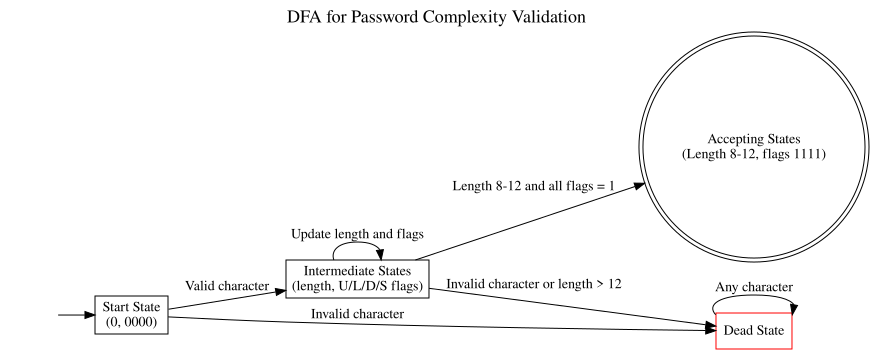


DFA ACCEPTANCE CONDITION:
Length must be between 8 and 12.
All four category flags must be present: 1111.


In [12]:
# TASK 2 - APPLICATION 2
# Password Complexity Validation using DFA

import pandas as pd
from graphviz import Digraph
from IPython.display import display

# Character categories
SPECIAL_CHARS = "!@#$%^&*()-_+=[]{};:,.?/"

# DFA state = (length, category_flags)
# Flags: Uppercase, Lowercase, Digit, Special
# Example: (8, 15) means length 8 and all four categories found.

START_STATE = (0, 0)
DEAD_STATE = "DEAD"

ACCEPT_MASK = 15


# Identify character category
def get_category(char):

    if 'A' <= char <= 'Z':
        return 1

    elif 'a' <= char <= 'z':
        return 2

    elif '0' <= char <= '9':
        return 4

    elif char in SPECIAL_CHARS:
        return 8

    else:
        return 0


# DFA transition function
def password_transition(state, char):

    if state == DEAD_STATE:
        return DEAD_STATE

    category = get_category(char)

    if category == 0:
        return DEAD_STATE

    length, flags = state
    new_length = length + 1

    if new_length > 12:
        return DEAD_STATE

    new_flags = flags | category

    return (new_length, new_flags)


# Password validation
def validate_password(password):

    current_state = START_STATE
    trace = [current_state]

    for char in password:
        current_state = password_transition(current_state, char)
        trace.append(current_state)

    accepted = (
        current_state != DEAD_STATE
        and 8 <= current_state[0] <= 12
        and current_state[1] == ACCEPT_MASK
    )

    return accepted, trace


# Convert state into readable format
def format_state(state):

    if state == DEAD_STATE:
        return "DEAD"

    length, flags = state

    categories = [
        "U" if flags & 1 else "-",
        "L" if flags & 2 else "-",
        "D" if flags & 4 else "-",
        "S" if flags & 8 else "-"
    ]

    return f"({length}, {''.join(categories)})"


# Test cases: 5 accepted and 5 rejected
test_passwords = [
    "Hello@123",
    "Student#9",
    "Abcd@1234",
    "Python$456",
    "Tech@2026",
    "hello123",
    "HELLO@123",
    "Hello@1",
    "Hello@1234567",
    "Hello 123"
]

results = []

for password in test_passwords:

    accepted, trace = validate_password(password)

    results.append({
        "Password": password,
        "Result": "ACCEPTED" if accepted else "REJECTED",
        "State Trace": " → ".join(
            format_state(state) for state in trace
        )
    })

df_password = pd.DataFrame(results)

print("PASSWORD VALIDATION USING DFA")
print("Length: 8-12 | Uppercase | Lowercase | Digit | Special Character")
print("-" * 90)

display(df_password)


# Draw a compact symbolic DFA diagram
password_dfa = Digraph("Password_DFA", format="png")

password_dfa.attr(
    rankdir="LR",
    label="DFA for Password Complexity Validation",
    labelloc="t",
    fontsize="18"
)

password_dfa.attr("node", shape="box")

password_dfa.node("start", shape="none", label="")
password_dfa.node("q0", "Start State\n(0, 0000)")
password_dfa.node(
    "qvalid",
    "Intermediate States\n(length, U/L/D/S flags)"
)
password_dfa.node(
    "qaccept",
    "Accepting States\n(Length 8-12, flags 1111)",
    shape="doublecircle"
)
password_dfa.node("dead", "Dead State", color="red")

password_dfa.edge("start", "q0")
password_dfa.edge(
    "q0", "qvalid",
    label="Valid character"
)
password_dfa.edge(
    "qvalid", "qvalid",
    label="Update length and flags"
)
password_dfa.edge(
    "qvalid", "qaccept",
    label="Length 8-12 and all flags = 1"
)
password_dfa.edge(
    "q0", "dead",
    label="Invalid character"
)
password_dfa.edge(
    "qvalid", "dead",
    label="Invalid character or length > 12"
)
password_dfa.edge("dead", "dead", label="Any character")

display(password_dfa)

print("\nDFA ACCEPTANCE CONDITION:")
print("Length must be between 8 and 12.")
print("All four category flags must be present: 1111.")

EMAIL VALIDATION USING DFA
Format: Alphanumeric@Alphanumeric.TLD
TLD must contain at least two letters.


,Email,Result,State Trace
0,user@example.com,ACCEPTED,q0 → q1 → q1 → q1 → q1 → q2 → q2 → q2 → q2 → q...
1,a1@b2.in,ACCEPTED,q0 → q1 → q1 → q2 → q2 → q2 → q3 → q4 → q5
2,student123@srm.edu,ACCEPTED,q0 → q1 → q1 → q1 → q1 → q1 → q1 → q1 → q1 → q...
3,hello@world.org,ACCEPTED,q0 → q1 → q1 → q1 → q1 → q1 → q2 → q2 → q2 → q...
4,x@y.co,ACCEPTED,q0 → q1 → q2 → q2 → q3 → q4 → q5
5,userexample.com,REJECTED,q0 → q1 → q1 → q1 → q1 → q1 → q1 → q1 → q1 → q...
6,@example.com,REJECTED,q0 → DEAD → DEAD → DEAD → DEAD → DEAD → DEAD →...
7,user@.com,ACCEPTED,q0 → q1 → q1 → q1 → q1 → q2 → q3 → q4 → q5 → q5
8,user@example.c,REJECTED,q0 → q1 → q1 → q1 → q1 → q2 → q2 → q2 → q2 → q...
9,user@example.123,REJECTED,q0 → q1 → q1 → q1 → q1 → q2 → q2 → q2 → q2 → q...


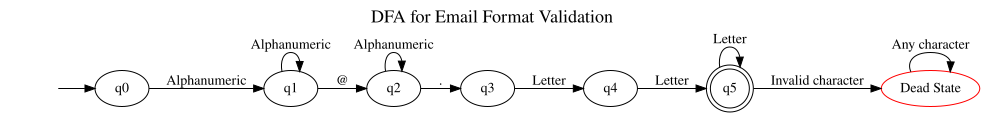

Accepting State: q5
Unspecified transitions lead to the dead state.


In [13]:
# TASK 2 - APPLICATION 3
# Email Format Validation using DFA

import pandas as pd
from graphviz import Digraph
from IPython.display import display

def email_transition(state, char):

    if state == "DEAD":
        return "DEAD"

    alphanumeric = char.isascii() and char.isalnum()
    alphabet = char.isascii() and char.isalpha()

    if state == "q0":
        return "q1" if alphanumeric else "DEAD"

    elif state == "q1":
        if alphanumeric:
            return "q1"
        elif char == "@":
            return "q2"
        return "DEAD"

    elif state == "q2":
        if alphanumeric:
            return "q2"
        elif char == ".":
            return "q3"
        return "DEAD"

    elif state == "q3":
        return "q4" if alphabet else "DEAD"

    elif state == "q4":
        return "q5" if alphabet else "DEAD"

    elif state == "q5":
        return "q5" if alphabet else "DEAD"


def validate_email(email):

    state = "q0"
    trace = [state]

    for char in email:
        state = email_transition(state, char)
        trace.append(state)

    return state == "q5", trace


email_tests = [
    "user@example.com",
    "a1@b2.in",
    "student123@srm.edu",
    "hello@world.org",
    "x@y.co",
    "userexample.com",
    "@example.com",
    "user@.com",
    "user@example.c",
    "user@example.123",
    "user@exam..com"
]

email_results = []

for email in email_tests:

    accepted, trace = validate_email(email)

    email_results.append({
        "Email": email,
        "Result": "ACCEPTED" if accepted else "REJECTED",
        "State Trace": " → ".join(trace)
    })

df_email = pd.DataFrame(email_results)

print("EMAIL VALIDATION USING DFA")
print("Format: Alphanumeric@Alphanumeric.TLD")
print("TLD must contain at least two letters.")
display(df_email)


# DFA Diagram

email_dfa = Digraph("Email_DFA", format="png")

email_dfa.attr(
    rankdir="LR",
    label="DFA for Email Format Validation",
    labelloc="t",
    fontsize="18"
)

email_dfa.node("start", shape="none", label="")

email_dfa.node("q0", "q0")
email_dfa.node("q1", "q1")
email_dfa.node("q2", "q2")
email_dfa.node("q3", "q3")
email_dfa.node("q4", "q4")
email_dfa.node("q5", "q5", shape="doublecircle")
email_dfa.node("DEAD", "Dead State", color="red")

email_dfa.edge("start", "q0")
email_dfa.edge("q0", "q1", label="Alphanumeric")
email_dfa.edge("q1", "q1", label="Alphanumeric")
email_dfa.edge("q1", "q2", label="@")
email_dfa.edge("q2", "q2", label="Alphanumeric")
email_dfa.edge("q2", "q3", label=".")
email_dfa.edge("q3", "q4", label="Letter")
email_dfa.edge("q4", "q5", label="Letter")
email_dfa.edge("q5", "q5", label="Letter")

email_dfa.edge("q5", "DEAD", label="Invalid character")
email_dfa.edge("DEAD", "DEAD", label="Any character")

display(email_dfa)

print("Accepting State: q5")
print("Unspecified transitions lead to the dead state.")

In [14]:
# TASK 3 - CASE STUDY 1
# Balanced Brackets using Pushdown Automaton

import pandas as pd
from IPython.display import display

opening = ["(", "{", "["]

matching = {
    ")": "(",
    "}": "{",
    "]": "["
}


def validate_brackets(expression):

    stack = []
    trace = []

    trace.append({
        "Symbol": "START",
        "Stack": "BOTTOM",
        "Action": "Initialize PDA"
    })

    accepted = True

    for char in expression:

        if char in opening:
            stack.append(char)
            action = "Push " + char

        elif char in matching:

            if stack and stack[-1] == matching[char]:
                removed = stack.pop()
                action = "Pop " + removed

            else:
                action = "REJECT - Mismatched closing bracket"
                accepted = False

                trace.append({
                    "Symbol": char,
                    "Stack": "BOTTOM " + "".join(stack),
                    "Action": action
                })

                break

        else:
            action = "REJECT - Invalid character"
            accepted = False

            trace.append({
                "Symbol": char,
                "Stack": "BOTTOM " + "".join(stack),
                "Action": action
            })

            break

        trace.append({
            "Symbol": char,
            "Stack": "BOTTOM " + "".join(stack),
            "Action": action
        })

    if accepted and stack:
        accepted = False
        action = "REJECT - Unmatched opening brackets"

    elif accepted:
        action = "ACCEPT - Stack is empty"

    trace.append({
        "Symbol": "END",
        "Stack": "BOTTOM " + "".join(stack),
        "Action": action
    })

    return accepted, trace


bracket_tests = [
    "()",
    "([])",
    "{[()]}",
    "(()())",
    "[{}]",
    "(",
    ")",
    "([)]",
    "{[(])}",
    "(()",
    "a+b"
]

bracket_results = []

for expression in bracket_tests:

    accepted, trace = validate_brackets(expression)

    bracket_results.append({
        "Input": repr(expression),
        "Result": "ACCEPTED" if accepted else "REJECTED",
        "Stack Trace": " | ".join(
            f"{x['Symbol']}:{x['Stack']} ({x['Action']})"
            for x in trace
        )
    })

df_brackets = pd.DataFrame(bracket_results)

print("BALANCED BRACKETS VALIDATION USING PDA")
display(df_brackets)


# Display detailed example

print("\nDETAILED PDA STACK EXECUTION FOR {[()]}")
accepted, example_trace = validate_brackets("{[()]}")

display(pd.DataFrame(example_trace))

print("\nCFG GRAMMAR:")
print("S → SS | (S) | [S] | {S} | ε")

BALANCED BRACKETS VALIDATION USING PDA


,Input,Result,Stack Trace
0,'()',ACCEPTED,START:BOTTOM (Initialize PDA) | (:BOTTOM ( (Pu...
1,'([])',ACCEPTED,START:BOTTOM (Initialize PDA) | (:BOTTOM ( (Pu...
2,'{[()]}',ACCEPTED,START:BOTTOM (Initialize PDA) | {:BOTTOM { (Pu...
3,'(()())',ACCEPTED,START:BOTTOM (Initialize PDA) | (:BOTTOM ( (Pu...
4,'[{}]',ACCEPTED,START:BOTTOM (Initialize PDA) | [:BOTTOM [ (Pu...
5,'(',REJECTED,START:BOTTOM (Initialize PDA) | (:BOTTOM ( (Pu...
6,')',REJECTED,START:BOTTOM (Initialize PDA) | ):BOTTOM (REJ...
7,'([)]',REJECTED,START:BOTTOM (Initialize PDA) | (:BOTTOM ( (Pu...
8,'{[(])}',REJECTED,START:BOTTOM (Initialize PDA) | {:BOTTOM { (Pu...
9,'(()',REJECTED,START:BOTTOM (Initialize PDA) | (:BOTTOM ( (Pu...



DETAILED PDA STACK EXECUTION FOR {[()]}


,Symbol,Stack,Action
0,START,BOTTOM,Initialize PDA
1,{,BOTTOM {,Push {
2,[,BOTTOM {[,Push [
3,(,BOTTOM {[(,Push (
4,),BOTTOM {[,Pop (
5,],BOTTOM {,Pop [
6,},BOTTOM,Pop {
7,END,BOTTOM,ACCEPT - Stack is empty



CFG GRAMMAR:
S → SS | (S) | [S] | {S} | ε


In [15]:
# TASK 3 - CASE STUDY 2
# Arithmetic Expression Validation using CFG and PDA-style Parsing

import re
import pandas as pd
from IPython.display import display


# Tokenization

token_pattern = re.compile(
    r'\s*(?:(\d+(?:\.\d+)?)|([A-Za-z_][A-Za-z0-9_]*)|([()+\-*/]))'
)


def tokenize_expression(expression):

    tokens = []
    position = 0

    while position < len(expression):

        if expression[position:].strip() == "":
            break

        match = token_pattern.match(expression, position)

        if not match:
            return None

        if match.group(1):
            tokens.append(("num", match.group(1)))

        elif match.group(2):
            tokens.append(("id", match.group(2)))

        else:
            tokens.append((match.group(3), match.group(3)))

        position = match.end()

    return tokens


# Predictive parsing table

parsing_table = {

    "E": {
        "id": ["T", "E'"],
        "num": ["T", "E'"],
        "(": ["T", "E'"]
    },

    "E'": {
        "+": ["+", "T", "E'"],
        "-": ["-", "T", "E'"],
        ")": [],
        "$": []
    },

    "T": {
        "id": ["F", "T'"],
        "num": ["F", "T'"],
        "(": ["F", "T'"]
    },

    "T'": {
        "*": ["*", "F", "T'"],
        "/": ["/", "F", "T'"],
        "+": [],
        "-": [],
        ")": [],
        "$": []
    },

    "F": {
        "(": ["(", "E", ")"],
        "id": ["id"],
        "num": ["num"]
    }
}


terminals = {"id", "num", "+", "-", "*", "/", "(", ")", "$"}


def parse_expression(expression):

    tokens = tokenize_expression(expression)

    if tokens is None:
        return False, [], "Invalid character"

    tokens = tokens + [("$", "$")]

    stack = ["$", "E"]
    index = 0

    trace = []
    accepted = False

    for step in range(200):

        top = stack[-1]
        lookahead = tokens[index][0]

        stack_view = " ".join(reversed(stack))
        remaining = " ".join(x[1] for x in tokens[index:])

        if top == "$" and lookahead == "$":
            action = "ACCEPT"
            accepted = True

        elif top in terminals:

            if top == lookahead:
                stack.pop()
                index += 1
                action = "Match " + top

            else:
                action = "REJECT - Terminal mismatch"

        else:

            production = parsing_table.get(top, {}).get(
                lookahead, None
            )

            if production is None:
                action = "REJECT - No production available"

            else:
                stack.pop()

                for symbol in reversed(production):
                    stack.append(symbol)

                if production:
                    action = top + " → " + " ".join(production)
                else:
                    action = top + " → ε"

        trace.append({
            "Step": step + 1,
            "Stack (Top First)": stack_view,
            "Remaining Input": remaining,
            "Action": action
        })

        if accepted:
            break

        if action.startswith("REJECT"):
            break

    return accepted, trace, "Accepted" if accepted else "Rejected"


# Test cases

arithmetic_tests = [
    "a+b",
    "(a+b)*c",
    "12+3*4",
    "a*(b-c)/d",
    "((x))",
    "10.5/2.5",
    "a+",
    "*a",
    "(a+b",
    "a b",
    "a++b"
]

arithmetic_results = []

for expression in arithmetic_tests:

    accepted, trace, message = parse_expression(expression)

    arithmetic_results.append({
        "Expression": expression,
        "Result": "ACCEPTED" if accepted else "REJECTED",
        "Parsing Status": message
    })

df_arithmetic = pd.DataFrame(arithmetic_results)

print("ARITHMETIC EXPRESSION VALIDATION")
display(df_arithmetic)


# Detailed parsing trace

print("\nDETAILED PDA-STYLE PARSING TRACE FOR (a+b)*c")

accepted, trace, message = parse_expression("(a+b)*c")

display(pd.DataFrame(trace))

print("\nCFG PRODUCTIONS:")
print("E  → T E'")
print("E' → + T E' | - T E' | ε")
print("T  → F T'")
print("T' → * F T' | / F T' | ε")
print("F  → (E) | id | num")

ARITHMETIC EXPRESSION VALIDATION


,Expression,Result,Parsing Status
0,a+b,ACCEPTED,Accepted
1,(a+b)*c,ACCEPTED,Accepted
2,12+3*4,ACCEPTED,Accepted
3,a*(b-c)/d,ACCEPTED,Accepted
4,((x)),ACCEPTED,Accepted
5,10.5/2.5,ACCEPTED,Accepted
6,a+,REJECTED,Rejected
7,*a,REJECTED,Rejected
8,(a+b,REJECTED,Rejected
9,a b,REJECTED,Rejected



DETAILED PDA-STYLE PARSING TRACE FOR (a+b)*c


,Step,Stack (Top First),Remaining Input,Action
0,1,E $,( a + b ) * c $,E → T E'
1,2,T E' $,( a + b ) * c $,T → F T'
2,3,F T' E' $,( a + b ) * c $,F → ( E )
3,4,( E ) T' E' $,( a + b ) * c $,Match (
4,5,E ) T' E' $,a + b ) * c $,E → T E'
5,6,T E' ) T' E' $,a + b ) * c $,T → F T'
6,7,F T' E' ) T' E' $,a + b ) * c $,F → id
7,8,id T' E' ) T' E' $,a + b ) * c $,Match id
8,9,T' E' ) T' E' $,+ b ) * c $,T' → ε
9,10,E' ) T' E' $,+ b ) * c $,E' → + T E'



CFG PRODUCTIONS:
E  → T E'
E' → + T E' | - T E' | ε
T  → F T'
T' → * F T' | / F T' | ε
F  → (E) | id | num


In [16]:
# TASK 3 - CASE STUDY 3
# Palindrome Recognition using Non-Deterministic PDA

from collections import deque
import pandas as pd
from IPython.display import display


def validate_palindrome(string):

    if any(char not in "ab" for char in string):
        return False, []

    start = ("push", 0, ("Z",))

    queue = deque([start])

    parent = {start: None}

    accepting_config = None

    while queue:

        state, index, stack = queue.popleft()

        # Acceptance condition
        if (
            state == "match"
            and index == len(string)
            and stack == ("Z",)
        ):
            accepting_config = (state, index, stack)
            break

        def add_config(new_config, action):

            if new_config not in parent:
                parent[new_config] = ((state, index, stack), action)
                queue.append(new_config)

        if state == "push":

            # Guess the middle for even-length palindrome
            add_config(
                ("match", index, stack),
                "Epsilon transition: Guess midpoint"
            )

            if index < len(string):

                # Guess the middle symbol for odd-length palindrome
                add_config(
                    ("match", index + 1, stack),
                    "Consume " + string[index] + " as middle symbol"
                )

                # Push first-half characters
                add_config(
                    ("push", index + 1, stack + (string[index],)),
                    "Read " + string[index] + " and push onto stack"
                )

        elif state == "match":

            if index < len(string) and len(stack) > 1:

                if string[index] == stack[-1]:

                    add_config(
                        ("match", index + 1, stack[:-1]),
                        "Match " + string[index] + " and pop"
                    )

    if accepting_config is None:
        return False, []

    # Reconstruct successful execution path

    path = []
    current = accepting_config

    while parent[current] is not None:

        previous, action = parent[current]

        path.append((current, action))

        current = previous

    path.reverse()

    trace = [{
        "State": "push",
        "Input Position": 0,
        "Stack": "Z",
        "Action": "Start"
    }]

    for config, action in path:

        state, index, stack = config

        trace.append({
            "State": state,
            "Input Position": index,
            "Stack": "".join(stack),
            "Action": action
        })

    return True, trace


# Test cases

palindrome_tests = [
    "",
    "a",
    "b",
    "aa",
    "aba",
    "abba",
    "baab",
    "aab",
    "abb",
    "abab",
    "baa"
]

palindrome_results = []

for string in palindrome_tests:

    accepted, trace = validate_palindrome(string)

    palindrome_results.append({
        "Input": repr(string),
        "Result": "ACCEPTED" if accepted else "REJECTED"
    })

df_palindrome = pd.DataFrame(palindrome_results)

print("PALINDROME RECOGNITION USING NPDA")
display(df_palindrome)


# Detailed successful execution

print("\nNPDA EXECUTION FOR abba")

accepted, trace = validate_palindrome("abba")

display(pd.DataFrame(trace))


print("\nCFG FOR PALINDROME LANGUAGE:")
print("S → aSa | bSb | a | b | ε")

print("\nExample derivation:")
print("S ⇒ aSa")
print("  ⇒ abSba")
print("  ⇒ abba")

PALINDROME RECOGNITION USING NPDA


,Input,Result
0,'',ACCEPTED
1,'a',ACCEPTED
2,'b',ACCEPTED
3,'aa',ACCEPTED
4,'aba',ACCEPTED
5,'abba',ACCEPTED
6,'baab',ACCEPTED
7,'aab',REJECTED
8,'abb',REJECTED
9,'abab',REJECTED



NPDA EXECUTION FOR abba


,State,Input Position,Stack,Action
0,push,0,Z,Start
1,push,1,Za,Read a and push onto stack
2,push,2,Zab,Read b and push onto stack
3,match,2,Zab,Epsilon transition: Guess midpoint
4,match,3,Za,Match b and pop
5,match,4,Z,Match a and pop



CFG FOR PALINDROME LANGUAGE:
S → aSa | bSb | a | b | ε

Example derivation:
S ⇒ aSa
  ⇒ abSba
  ⇒ abba


In [17]:
# FINAL PROJECT RESULTS
# Combine Task 2 and Task 3 test results

import pandas as pd
from IPython.display import display


all_records = []


def collect_results(dataframe, task, application, input_column):

    if dataframe is None:
        return

    for _, row in dataframe.iterrows():

        all_records.append({
            "Task": task,
            "Application": application,
            "Input": row[input_column],
            "Result": row["Result"]
        })


# Task 2 applications

collect_results(
    globals().get("df_pin"),
    "Task 2",
    "ATM PIN Validation",
    "ATM PIN"
)

collect_results(
    globals().get("df_password"),
    "Task 2",
    "Password Validation",
    "Password"
)

collect_results(
    globals().get("df_email"),
    "Task 2",
    "Email Validation",
    "Email"
)


# Task 3 applications

collect_results(
    globals().get("df_brackets"),
    "Task 3",
    "Balanced Brackets PDA",
    "Input"
)

collect_results(
    globals().get("df_arithmetic"),
    "Task 3",
    "Arithmetic Expression Parser",
    "Expression"
)

collect_results(
    globals().get("df_palindrome"),
    "Task 3",
    "Palindrome NPDA",
    "Input"
)


# Combined results

df_final = pd.DataFrame(all_records)

print("=" * 65)
print("FORMAL LANGUAGE AND AUTOMATA - CLA 2 PROJECT RESULTS")
print("=" * 65)

display(df_final)


# Summary of accepted and rejected strings

print("\nAPPLICATION-WISE PERFORMANCE SUMMARY")

summary = df_final.groupby(
    ["Application", "Result"]
).size().unstack(fill_value=0)

display(summary)


# Save CSV files

df_final.to_csv("FLA_All_Test_Results.csv", index=False)

df_task2 = df_final[df_final["Task"] == "Task 2"]
df_task3 = df_final[df_final["Task"] == "Task 3"]

df_task2.to_csv("FLA_Task2_Results.csv", index=False)
df_task3.to_csv("FLA_Task3_Results.csv", index=False)


# Save individual detailed results

for name in [
    "df_pin",
    "df_password",
    "df_email",
    "df_brackets",
    "df_arithmetic",
    "df_palindrome"
]:

    if name in globals():
        globals()[name].to_csv(name + "_Detailed.csv", index=False)


print("\nPROJECT EXECUTION COMPLETED!")
print("Generated files:")
print("1. FLA_All_Test_Results.csv")
print("2. FLA_Task2_Results.csv")
print("3. FLA_Task3_Results.csv")
print("4. Individual application result CSV files")

FORMAL LANGUAGE AND AUTOMATA - CLA 2 PROJECT RESULTS


,Task,Application,Input,Result
0,Task 2,ATM PIN Validation,'1234',ACCEPTED
1,Task 2,ATM PIN Validation,'0000',ACCEPTED
2,Task 2,ATM PIN Validation,'9876',ACCEPTED
3,Task 2,ATM PIN Validation,'2468',ACCEPTED
4,Task 2,ATM PIN Validation,'1357',ACCEPTED
...,...,...,...,...
59,Task 3,Palindrome NPDA,'baab',ACCEPTED
60,Task 3,Palindrome NPDA,'aab',REJECTED
61,Task 3,Palindrome NPDA,'abb',REJECTED
62,Task 3,Palindrome NPDA,'abab',REJECTED



APPLICATION-WISE PERFORMANCE SUMMARY


Result,ACCEPTED,REJECTED
Application,,
ATM PIN Validation,5,5
Arithmetic Expression Parser,6,5
Balanced Brackets PDA,5,6
Email Validation,6,5
Palindrome NPDA,7,4
Password Validation,5,5



PROJECT EXECUTION COMPLETED!
Generated files:
1. FLA_All_Test_Results.csv
2. FLA_Task2_Results.csv
3. FLA_Task3_Results.csv
4. Individual application result CSV files


In [18]:
import pandas as pd
import os
import zipfile
from google.colab import files

# Find all DataFrames created in the notebook
dataframes = {
    name: obj
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

if not dataframes:
    print("No result DataFrames found. Run the project cells first.")
else:
    folder = "/content/FLA_CSV_Results"
    os.makedirs(folder, exist_ok=True)

    for name, df in dataframes.items():
        filename = f"{name}.csv"
        filepath = os.path.join(folder, filename)
        df.to_csv(filepath, index=False)
        print(f"Saved: {filename} | Rows: {len(df)}")

    # Compress all CSV files into one ZIP
    zip_path = "/content/FLA_All_CSV_Results.zip"

    with zipfile.ZipFile(zip_path, "w") as zipf:
        for filename in os.listdir(folder):
            zipf.write(
                os.path.join(folder, filename),
                arcname=filename
            )

    print("\nCSV export completed successfully!")
    files.download(zip_path)

Saved: df_pin.csv | Rows: 10
Saved: df_password.csv | Rows: 10
Saved: df_email.csv | Rows: 11
Saved: df_brackets.csv | Rows: 11
Saved: df_arithmetic.csv | Rows: 11
Saved: df_palindrome.csv | Rows: 11
Saved: df_final.csv | Rows: 64
Saved: summary.csv | Rows: 6
Saved: df_task2.csv | Rows: 31
Saved: df_task3.csv | Rows: 33
Saved: df.csv | Rows: 33
Saved: email_dfa_results.csv | Rows: 10

CSV export completed successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>